In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp

import numpyro
import numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS
from numpyro.infer.initialization import init_to_value

import corner

from sp import *

from jaxoplanet.starry.ylm import Ylm
from jaxoplanet.starry.surface import Surface
from jaxoplanet.starry.visualization import show_surface


/Users/sabina/Desktop/GitHub/StarryStarryProcessJaxoplanet/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
lmax = 5
r = np.deg2rad(20.0)
c = 0.1
nspots = 10.0
period = 1.0

ncurves = 5
ntimes = 500
ferr = 1e-3

# inc = np.pi / 4
obl = 0.0

t = jnp.linspace(0.0, 4.0, ntimes)
theta = 2.0 * jnp.pi * jnp.mod(t / period, 1.0)

MU_TRUE_DEG = 60.0
SIGMA_TRUE_DEG = 5.0

seed = 123

In [3]:
a_true, b_true = map(float, gauss_to_ab(MU_TRUE_DEG, SIGMA_TRUE_DEG))
alpha_true, beta_true = map(float, ab_to_alpha_beta(a_true, b_true))
mu_check, sigma_check = map(float, ab_to_latitude(a_true, b_true))

print("true a,b       =", a_true, b_true)
print("true alpha,beta=", alpha_true, beta_true)
print("recovered mu,sigma =", mu_check, sigma_check)


W1016 15:26:02.828388 2752451 cpp_gen_intrinsics.cc:74] Empty bitcode string provided for eigen. Optimizations relying on this IR will be disabled.


true a,b       = 0.3125631150885175 0.3557450107475467
true alpha,beta= 22.77426455563385 22.440931222300506
recovered mu,sigma = 60.00000000000071 4.9999999999999485


In [4]:
sp = StarryProcess(alpha_true,beta_true,contrast=c,r=r,nspots=nspots,lmax=lmax)

In [5]:
sp

In [6]:
key = jax.random.PRNGKey(42)

key, inc_key = jax.random.split(key)

cos_inc_true = jax.random.uniform(inc_key,shape=(ncurves,),minval=0.0,maxval=1.0)

inclinations_true = jnp.arccos(cos_inc_true)
inclinations_true_deg = jnp.rad2deg(inclinations_true)

print(inclinations_true_deg)

[42.08776302 56.82789458 86.5666494  71.21196314 17.26858604]


In [7]:
fluxes = []

for i in range(ncurves):
    M_i = sp.design_matrix(
        theta=theta,
        inc=inclinations_true[i],
        obl=obl,
        period=period,
    )

    key, sample_key = jax.random.split(key)
    ylm_samples = sp.sample_ylm(key=sample_key, nsamples=1)
    flux_i = sp.sample_flux(ylm_samples, M_i)

    fluxes.append(flux_i[0])

f_true = jnp.stack(fluxes)

key, noise_key = jax.random.split(key)
f = f_true + ferr * jax.random.normal(noise_key, shape=f_true.shape)

print(inclinations_true.shape)  
print(f.shape)                  

(5,)
(5, 500)


In [8]:
mean_ylm, cov_ylm = sp.moments()

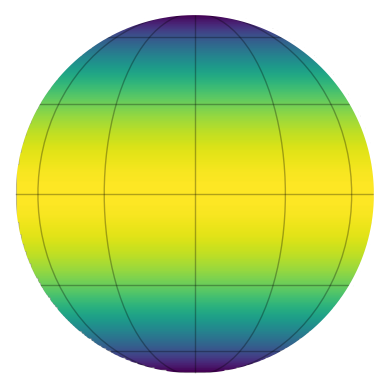

In [9]:
show_surface(mean_ylm)

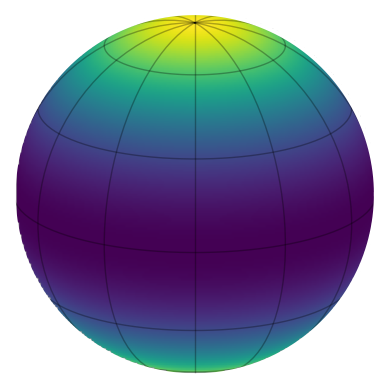

In [10]:
surface = Surface(y=Ylm.from_dense(mean_ylm),inc=inclinations_true[3],obl=obl,period=period)
show_surface(surface)

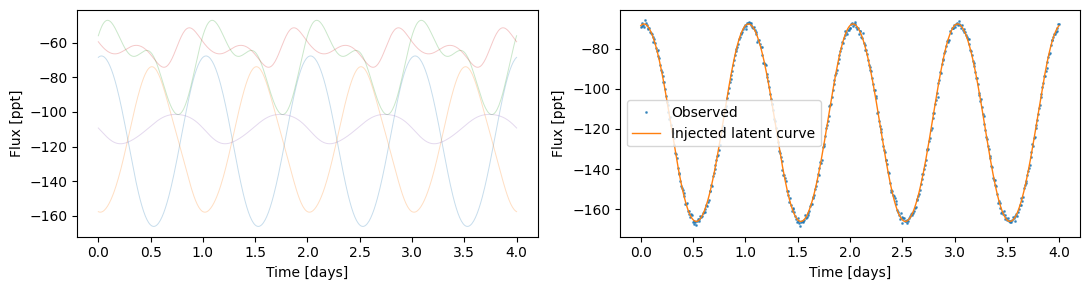

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
axes[0].plot(t, 1e3 * np.asarray(f_true).T, alpha=0.25, lw=0.7)
axes[0].set(xlabel='Time [days]', ylabel='Flux [ppt]')
axes[1].plot(t, 1e3 * np.asarray(f[0]), '.', ms=2, alpha=0.7, label='Observed')
axes[1].plot(t, 1e3 * np.asarray(f_true[0]), lw=1, label='Injected latent curve')
axes[1].set(xlabel='Time [days]', ylabel='Flux [ppt]')
axes[1].legend()
plt.tight_layout()
plt.show()

In [12]:
@jax.jit
def log_likelihood_abi(a, b, inclinations):
    alpha, beta = ab_to_alpha_beta(a, b)

    sp = StarryProcess(
        alpha,
        beta,
        contrast=c,
        r=r,
        nspots=nspots,
        lmax=lmax,
    )

    mean_ylm, cov_ylm = sp.moments()

    M_all = jax.vmap(
        lambda inc: sp.design_matrix(
            theta=theta,
            inc=inc,
            obl=obl,
            period=period,
        ))(inclinations)

    noise_var = ferr**2
    Dinv = 1.0 / noise_var
    ny = mean_ylm.shape[0]

    def one_curve_loglike(M, f_obs):
        mean_flux = M @ mean_ylm
        resid = f_obs - mean_flux

        # Woodbury identity in YLM space
        B = (jnp.eye(ny) + cov_ylm @ (Dinv * (M.T @ M)))

        rhs = cov_ylm @ (M.T @ (Dinv * resid))
        corr = M @ jnp.linalg.solve(B, rhs)

        quad = (jnp.sum(resid * (Dinv * resid)) - jnp.sum((Dinv * resid) * corr))

        _, logdet_B = jnp.linalg.slogdet(B)

        nt = f_obs.shape[0]
        logdet = nt * jnp.log(noise_var) + logdet_B
        constant = nt * jnp.log(2.0 * jnp.pi)

        return -0.5 * (quad + logdet + constant)

    individual_ll = jax.vmap(one_curve_loglike,in_axes=(0, 0))(M_all, f)

    return jnp.sum(individual_ll)

In [14]:
def model():
    a = numpyro.sample("a",dist.Uniform(1e-4, 1.0))
    b = numpyro.sample("b",dist.Uniform(1e-4, 1.0))

    cos_inc = numpyro.sample("cos_inc",dist.Uniform(0.0, 1.0).expand([ncurves]).to_event(1),)
    inclinations = jnp.arccos(cos_inc)
    ll = log_likelihood_abi(a, b, inclinations)

    numpyro.factor("loglik_factor", ll)
    numpyro.deterministic("inclinations",inclinations)

In [15]:
kernel = NUTS(model, target_accept_prob=0.8, dense_mass=False)
mcmc = MCMC(kernel, num_warmup=1000, num_samples=1000, num_chains=2, chain_method="sequential", progress_bar=True)

mcmc.run(jax.random.PRNGKey(seed + 1))
mcmc.print_summary()

sample: 100%|██████████| 2000/2000 [14:39<00:00,  2.27it/s, 32 steps of size 4.15e-02. acc. prob=0.83] 



                mean       std    median      5.0%     95.0%     n_eff     r_hat
         a      0.43      0.14      0.46      0.21      0.63    154.98      1.03
         b      0.47      0.13      0.49      0.28      0.65    150.64      1.03
cos_inc[0]      0.66      0.06      0.65      0.59      0.78    560.28      1.00
cos_inc[1]      0.54      0.09      0.54      0.36      0.64    141.69      1.01
cos_inc[2]      0.16      0.07      0.15      0.05      0.27    498.52      1.00
cos_inc[3]      0.27      0.09      0.26      0.13      0.40    351.76      1.01
cos_inc[4]      0.87      0.09      0.91      0.72      0.97    196.00      1.01

Number of divergences: 1005


In [16]:
samples = mcmc.get_samples()

In [17]:
a_post = samples["a"]
b_post = samples["b"]
inc_post = samples["inclinations"]

# Posterior median and 16th/84th percentiles for each curve
inc_median = jnp.median(inc_post, axis=0)
inc_interval = jnp.quantile(
    inc_post, jnp.array([0.16, 0.84]), axis=0
)

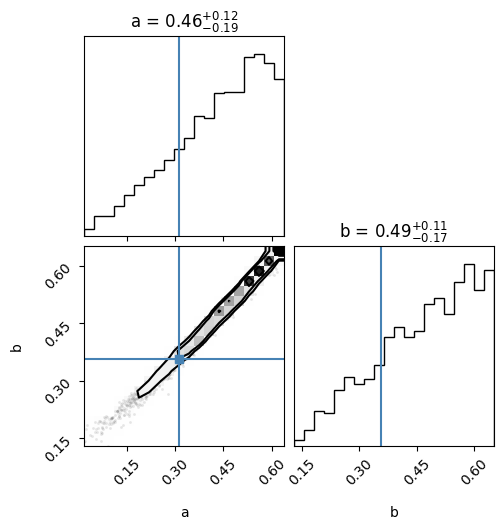

In [18]:
import corner

arr_ab = np.column_stack([np.asarray(samples['a']), np.asarray(samples['b'])])
fig = corner.corner(
    arr_ab,
    labels=['a', 'b'],
    truths=[a_true, b_true],
    show_titles=True,
)
plt.show()

In [19]:
mu_sigma_post = jax.vmap(ab_to_latitude)(samples['a'], samples['b'])
mu_post = np.asarray(mu_sigma_post[:, 0])
sigma_post = np.asarray(mu_sigma_post[:, 1])

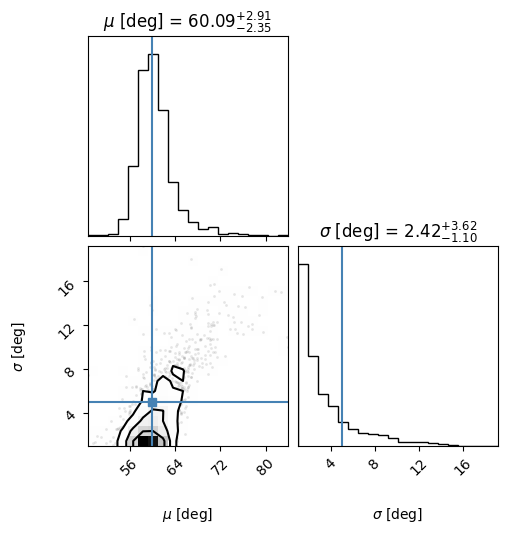

In [20]:
fig = corner.corner(
    np.column_stack([mu_post, sigma_post]),
    labels=[r'$\mu$ [deg]', r'$\sigma$ [deg]'],
    truths=[MU_TRUE_DEG, SIGMA_TRUE_DEG],
    show_titles=True,
)
plt.show()

In [21]:
inc_post = np.asarray(samples["inclinations"])

inc_true_deg = np.rad2deg(np.asarray(inclinations_true))

inc_post_deg = np.rad2deg(inc_post)

inc_median_deg = np.median(inc_post_deg, axis=0)
inc_lower_deg = np.percentile(inc_post_deg, 16, axis=0)
inc_upper_deg = np.percentile(inc_post_deg, 84, axis=0)

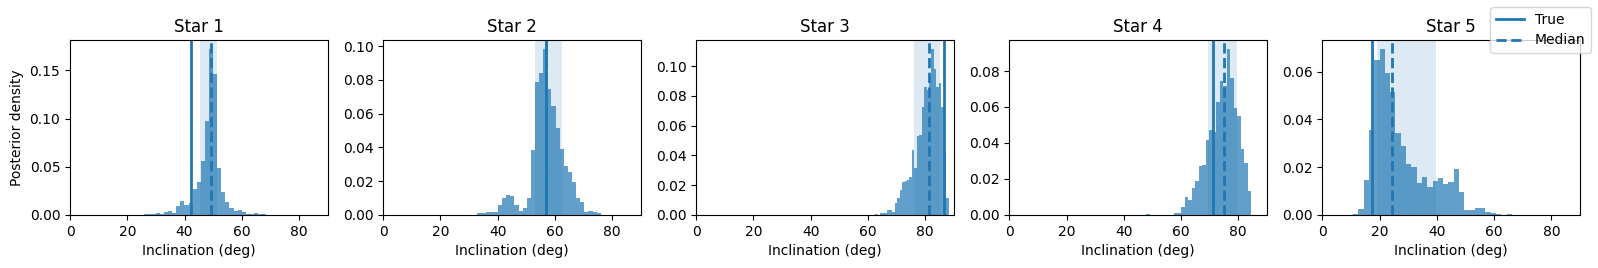

In [22]:
ncols = 5
nrows = int(np.ceil(ncurves / ncols))

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(16, 2.7 * nrows),
    sharex=True,
)

axes = np.asarray(axes).ravel()

for j in range(ncurves):
    ax = axes[j]

    ax.hist(
        inc_post_deg[:, j],
        bins=30,
        density=True,
        alpha=0.7,
    )

    ax.axvline(
        inc_true_deg[j],
        linestyle="-",
        linewidth=2,
        label="True",
    )

    ax.axvline(
        inc_median_deg[j],
        linestyle="--",
        linewidth=2,
        label="Median",
    )

    ax.axvspan(
        inc_lower_deg[j],
        inc_upper_deg[j],
        alpha=0.15,
    )

    ax.set_title(f"Star {j + 1}")
    ax.set_xlim(0, 90)
    ax.set_xlabel("Inclination (deg)")

    if j % ncols == 0:
        ax.set_ylabel("Posterior density")

for j in range(ncurves, len(axes)):
    fig.delaxes(axes[j])

handles, legend_labels = axes[0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc="upper right")

fig.tight_layout()
plt.show()

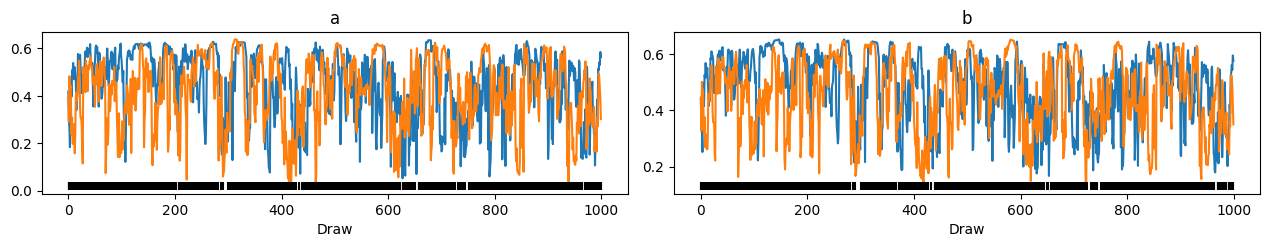

In [23]:
import arviz as az

idata = az.from_numpyro(mcmc)

az.plot_trace(idata,var_names=["a", "b"])

plt.tight_layout()
plt.show()

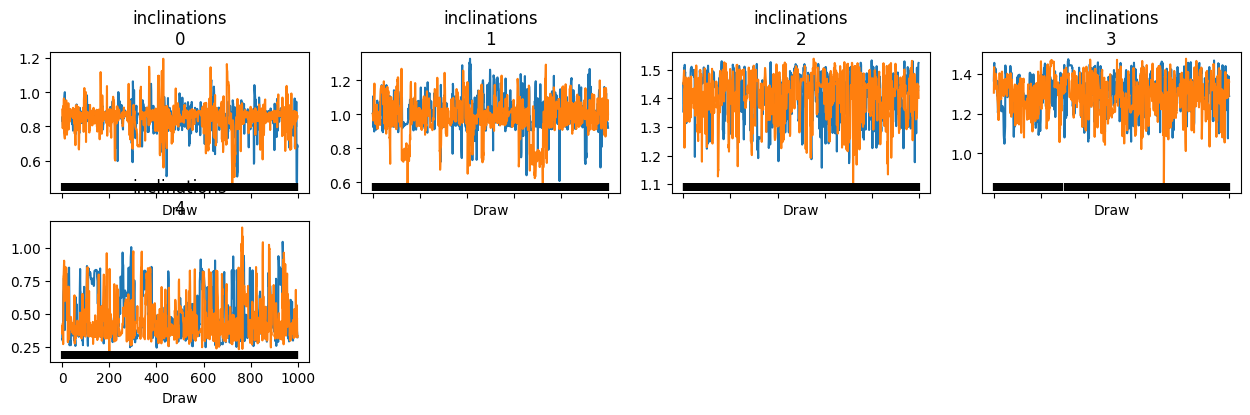

In [24]:
az.plot_trace(idata,var_names=["inclinations"])
plt.show()

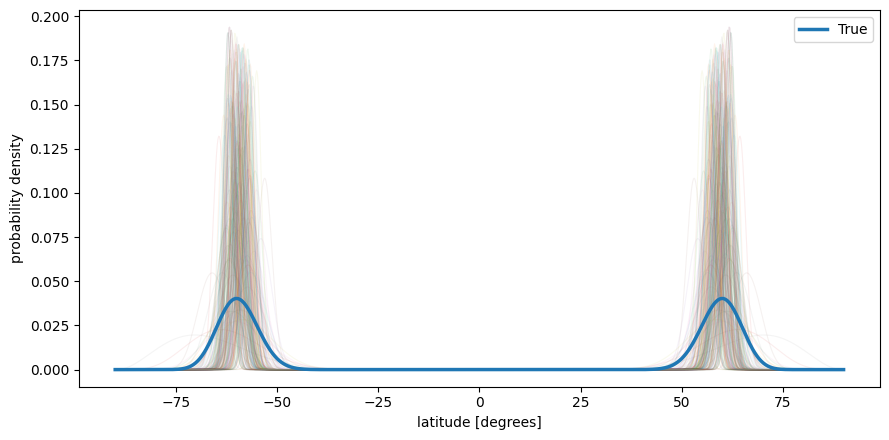

In [25]:
from scipy.stats import beta as beta_dist

phi = np.linspace(-90, 90, 1000)
phi_rad = np.deg2rad(phi)
x = np.cos(phi_rad)

alpha_post, beta_post = jax.vmap(ab_to_alpha_beta)(samples["a"], samples["b"])
alpha_post = np.asarray(alpha_post)
beta_post = np.asarray(beta_post)

alpha_true, beta_true = map(float, ab_to_alpha_beta(a_true, b_true))

jac = 0.5 * np.abs(np.sin(phi_rad)) * np.pi / 180.0
pdf_true = jac * beta_dist.pdf(x, alpha_true, beta_true)

fig, ax = plt.subplots(figsize=(9, 4.5))

nsamples_plot = min(200, len(alpha_post))
for alpha, beta in zip(alpha_post[:nsamples_plot], beta_post[:nsamples_plot]):
    pdf = jac * beta_dist.pdf(x, alpha, beta)
    ax.plot(phi, pdf, alpha=0.08, lw=0.8)

ax.plot(phi, pdf_true, lw=2.5, label="True")

ax.set_xlabel("latitude [degrees]")
ax.set_ylabel("probability density")
ax.legend()

plt.tight_layout()
plt.show()

In [27]:
n_draws = 100

a_post = np.asarray(samples["a"])
b_post = np.asarray(samples["b"])
inc_post = np.asarray(samples["inclinations"])

n_samples = len(a_post)
ncurves, nt = f.shape

rng = np.random.default_rng(42)
draw_indices = rng.choice(n_samples, size=min(n_draws, n_samples), replace=False)

key = jax.random.PRNGKey(123)
conditional_flux_draws = []

design_matrix_jit = jax.jit(lambda inc: sp.design_matrix(theta=theta, inc=inc, obl=obl, period=period))
conditional_flux_jit = jax.jit(StarryProcess.sample_conditional_flux, static_argnames=("nsamples",))

for idx in draw_indices:
    alpha, beta = ab_to_alpha_beta(a_post[idx], b_post[idx])

    sp_draw = StarryProcess(
        alpha,
        beta,
        contrast=c,
        r=r,
        nspots=nspots,
        lmax=lmax,
    )

    mean_ylm, cov_ylm = sp_draw.moments()

    fluxes_this_draw = []

    for j in range(ncurves):
        inc_j = inc_post[idx, j]

        M_j = design_matrix_jit(inc_j)
        key, sample_key = jax.random.split(key)
        flux_cond = conditional_flux_jit(
            mean_ylm=mean_ylm,
            cov_ylm=cov_ylm,
            f=f[j],
            M=M_j,
            ferr=ferr,
            key=sample_key,
            nsamples=1,
        )

        fluxes_this_draw.append(flux_cond[0, 0, :])

    conditional_flux_draws.append(jnp.stack(fluxes_this_draw))

conditional_flux_draws = np.asarray(jnp.stack(conditional_flux_draws))

In [41]:
conditional_flux_draws.shape

(100, 5, 500)

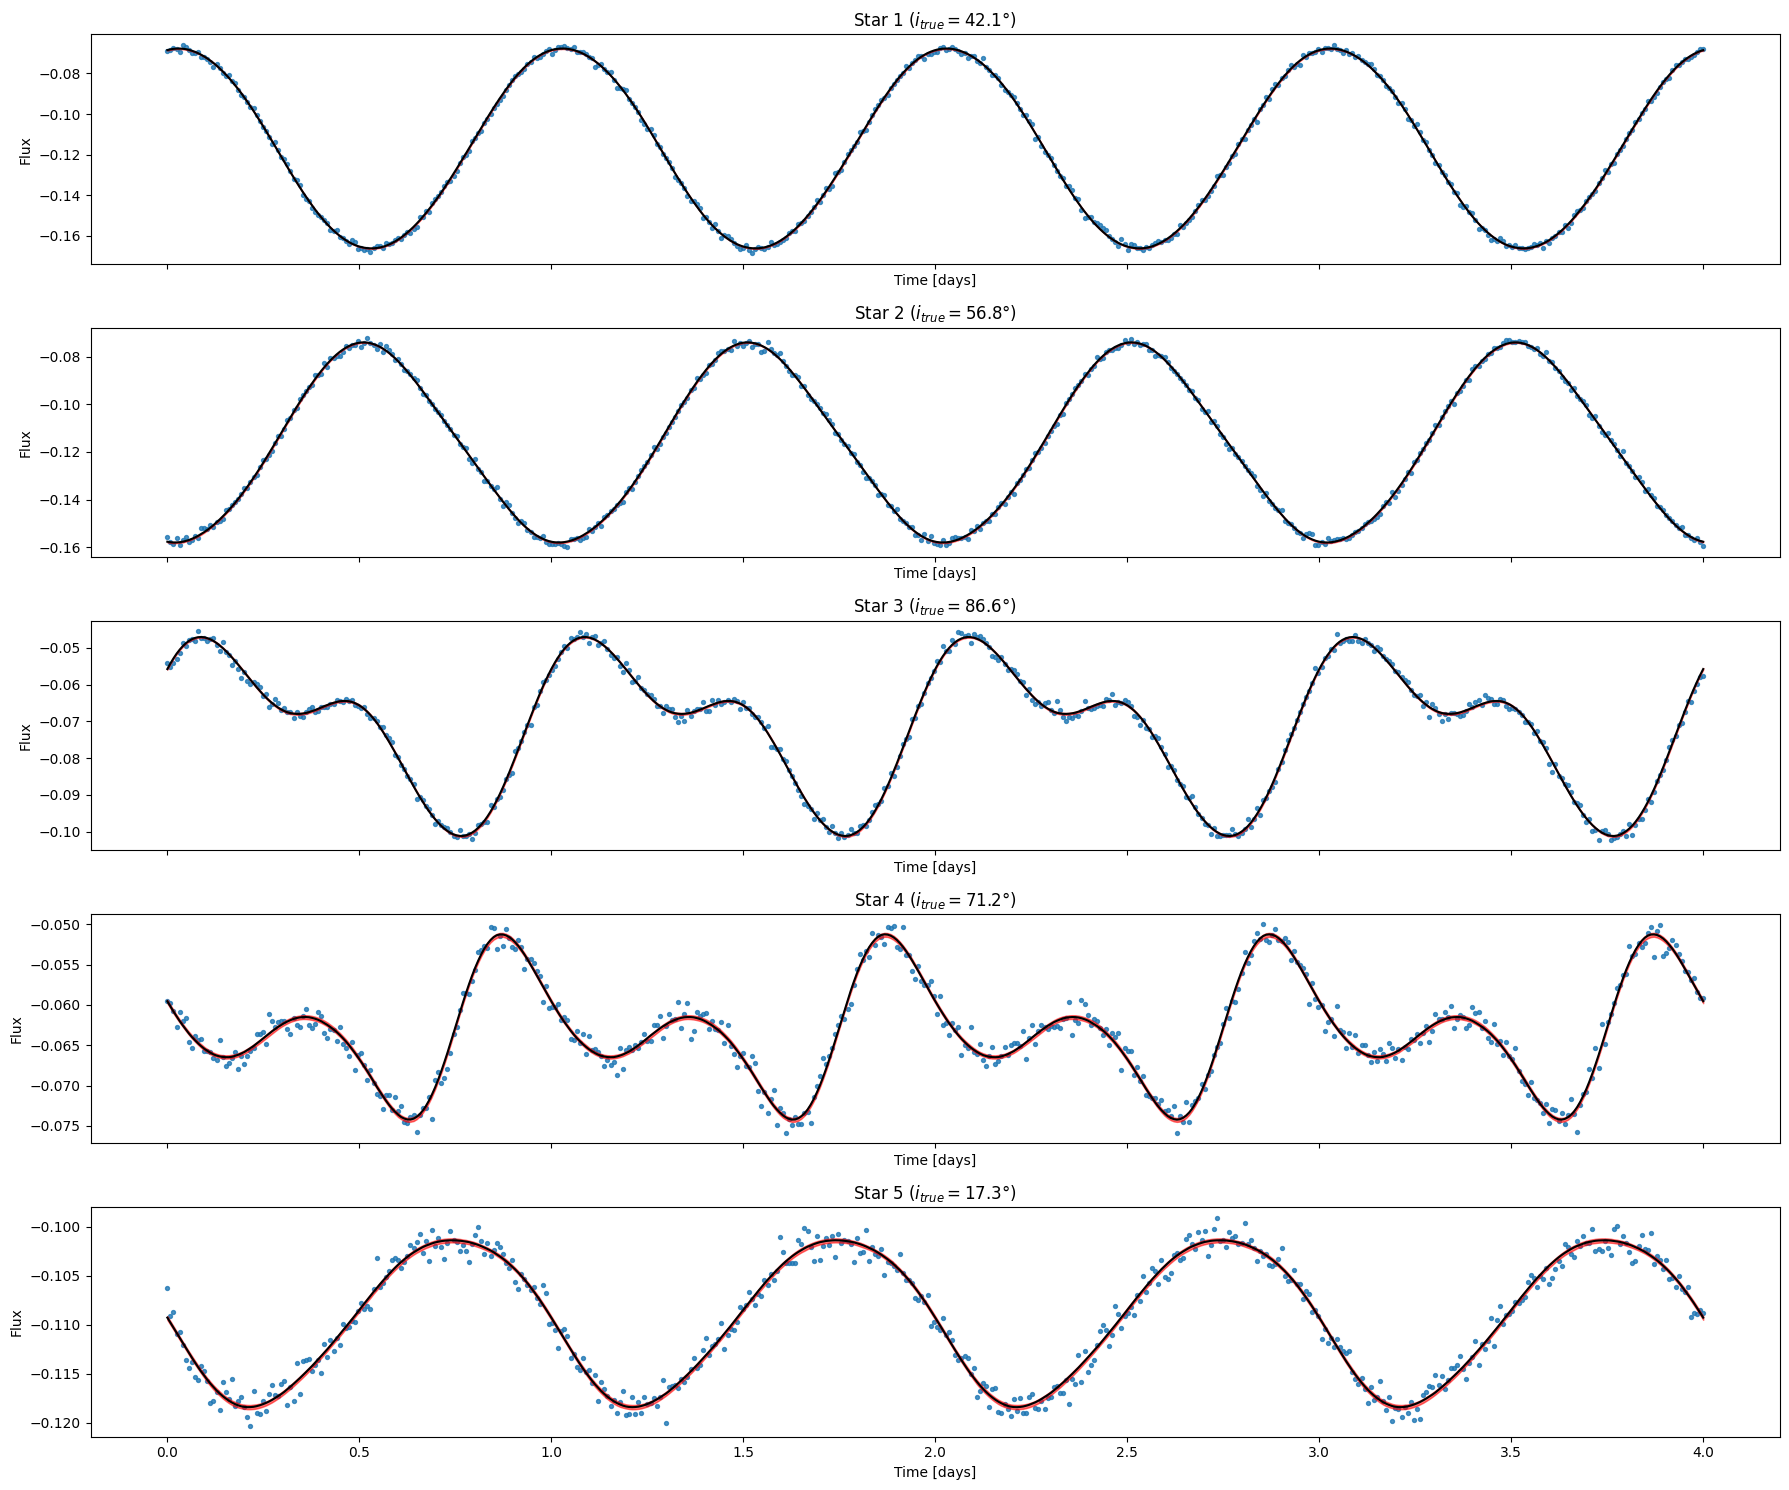

In [ ]:
ncols = 1
nrows = 5

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(18, 3 * nrows),
    sharex=True,
)

axes = np.asarray(axes).ravel()

x = np.unwrap(np.asarray(theta)) / (2 * np.pi) * period
f_obs = np.asarray(f)

for j, ax in enumerate(axes[:ncurves]):
    draws_j = conditional_flux_draws[:, j, :]

    flux_med = np.median(draws_j, axis=0)
    flux_lo = np.percentile(draws_j, 16, axis=0)
    flux_hi = np.percentile(draws_j, 84, axis=0)

    ax.scatter(
        x, f_obs[j],
        s=8,
        alpha=0.8,
        label="Observed",
    )

    ax.plot(
        x, flux_med,
        linewidth=1.5,
        label="conditional median",
        color='black'
    )

    ax.fill_between(
        x, flux_lo, flux_hi,
        alpha=0.55,
        label="1 sigma",
        color='red'
    )

    ax.set_title(
        f"Star {j + 1} "
        f"($i_{{true}}={np.rad2deg(float(inclinations_true[j])):.1f}°$)"
    )
    ax.set_xlabel("Time [days]")
    ax.set_ylabel("Flux")


fig.tight_layout()
plt.show()

In [46]:
flux_cond.shape

(1, 1, 500)

In [47]:
i = 0

f_obs = f[i]
flux_cond_i = flux_cond[i]

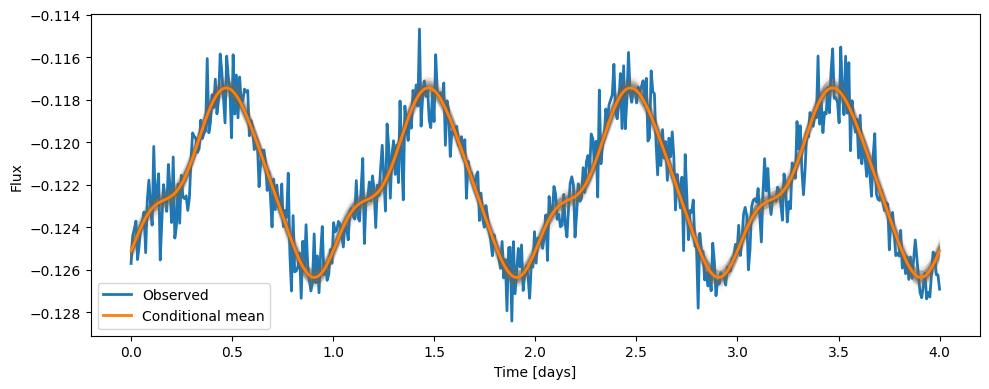

In [39]:
fig,ax = plt.subplots(figsize=(10,4))

ax.plot(t,f_obs,lw=2,label="Observed")
ax.plot(t,flux_cond_i.T,alpha=0.03,lw=0.7)
ax.plot(t,jnp.mean(flux_cond_i,axis=0),lw=2,label="Conditional mean")

ax.set_xlabel("Time [days]")
ax.set_ylabel("Flux")
ax.legend()

plt.tight_layout()
plt.show()